In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load train and test data
X_train = pd.read_csv("../data/X_train.csv")
X_test = pd.read_csv("../data/X_test.csv")

y_train = pd.read_csv("../data/y_train_reg.csv").squeeze("columns")
y_test = pd.read_csv("../data/y_test_reg.csv").squeeze("columns")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (58274, 9)
Testing features: (14569, 9)
Training target: (58274,)
Testing target: (14569,)


In [2]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['ChargerCompany', 'ChargerType', 'StartHour', 'StartDayOfWeek', 'StartMonth', 'StartYear', 'IsWeekend']
Categorical features: ['Location', 'TimePeriod']


C:\Users\ajaysaagar developer\AppData\Local\Temp\ipykernel_22212\3858876401.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [3]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [4]:
# Regression models
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        objective="reg:squarederror",
        n_jobs=-1
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=100,
        learning_rate=0.05,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

In [5]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = pipeline

    print(f"{name} completed - RMSE: {rmse:.4f}, MAE: {mae:.4f}, R2: {r2:.4f}")

Linear Regression completed - RMSE: 12.8593, MAE: 9.7997, R2: 0.1011


Decision Tree completed - RMSE: 15.0751, MAE: 11.0731, R2: -0.2354


Random Forest completed - RMSE: 13.7913, MAE: 10.3116, R2: -0.0340


Gradient Boosting completed - RMSE: 12.5702, MAE: 9.5200, R2: 0.1410


XGBoost completed - RMSE: 12.4907, MAE: 9.4391, R2: 0.1519


LightGBM completed - RMSE: 12.4593, MAE: 9.4177, R2: 0.1561


In [6]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df)

,Model,MAE,MSE,RMSE,R2
0,LightGBM,9.417685,155.234227,12.459303,0.156120
1,XGBoost,9.439106,156.017426,12.490694,0.151862
2,Gradient Boosting,9.520038,158.009109,12.570167,0.141035
3,Linear Regression,9.799700,165.362205,12.859324,0.101062
4,Random Forest,10.311565,190.199308,13.791277,-0.033957
5,Decision Tree,11.073055,227.257994,15.075079,-0.235414


In [7]:
os.makedirs("../outputs", exist_ok=True)

results_df.to_csv(
    "../outputs/regression_model_comparison.csv",
    index=False
)
print("Saved model comparison to ../outputs/regression_model_comparison.csv")

Saved model comparison to ../outputs/regression_model_comparison.csv


C:\Users\ajaysaagar developer\AppData\Local\Temp\ipykernel_22212\1695863537.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


Saved comparison chart to ../outputs/regression_model_comparison.png


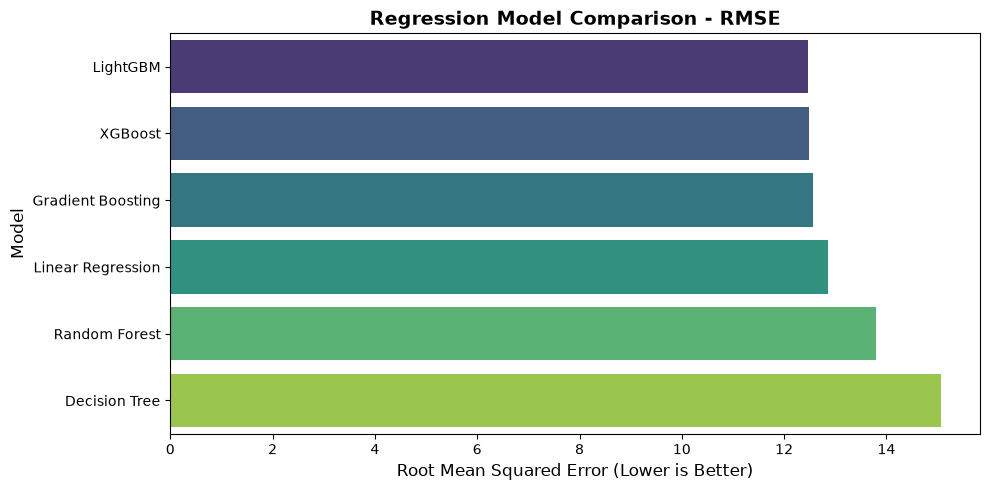

In [8]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="RMSE",
    y="Model",
    palette="viridis"
)

plt.title("Regression Model Comparison - RMSE", fontsize=14, fontweight="bold")
plt.xlabel("Root Mean Squared Error (Lower is Better)", fontsize=12)
plt.ylabel("Model", fontsize=12)

plt.savefig("../outputs/regression_model_comparison.png", dpi=300, bbox_inches="tight")
print("Saved comparison chart to ../outputs/regression_model_comparison.png")

plt.tight_layout()
plt.show()

In [9]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

os.makedirs("../trained_models", exist_ok=True)

joblib.dump(
    best_model,
    "../trained_models/best_regression_model.pkl"
)

print("Best Model:", best_model_name)
print("Model saved successfully!")

Best Model: LightGBM
Model saved successfully!


In [10]:
tree_models = [
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting",
    "XGBoost",
    "LightGBM"
]

importance_model_name = best_model_name if best_model_name in tree_models else "Random Forest"

importance_pipeline = trained_models[importance_model_name]

feature_names = (
    importance_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_values = (
    importance_pipeline
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.head(15))

,Feature,Importance
0,num__StartHour,593
1,num__StartMonth,492
2,num__StartDayOfWeek,243
3,num__ChargerCompany,225
4,cat__Location_market,168
5,num__ChargerType,165
6,cat__Location_apartment,132
7,cat__Location_camping,120
8,cat__Location_hotel,120
9,cat__Location_company,114


C:\Users\ajaysaagar developer\AppData\Local\Temp\ipykernel_22212\1377430029.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


Saved feature importance chart to ../outputs/regression_feature_importance.png


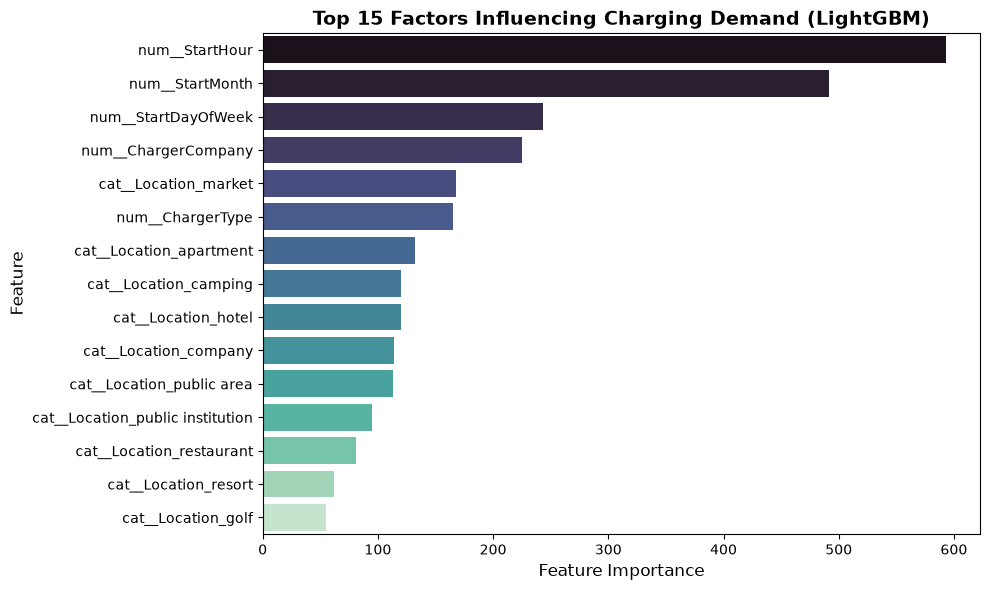

In [11]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature",
    palette="mako"
)

plt.title(f"Top 15 Factors Influencing Charging Demand ({importance_model_name})", fontsize=14, fontweight="bold")
plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("Feature", fontsize=12)

plt.savefig("../outputs/regression_feature_importance.png", dpi=300, bbox_inches="tight")
print("Saved feature importance chart to ../outputs/regression_feature_importance.png")

plt.tight_layout()
plt.show()

===== Regression Model Evaluation =====
Model: LightGBM
MAE  : 9.4177
MSE  : 155.2342
RMSE : 12.4593
R2   : 0.1561


Saved actual vs predicted chart to ../outputs/regression_actual_vs_predicted.png


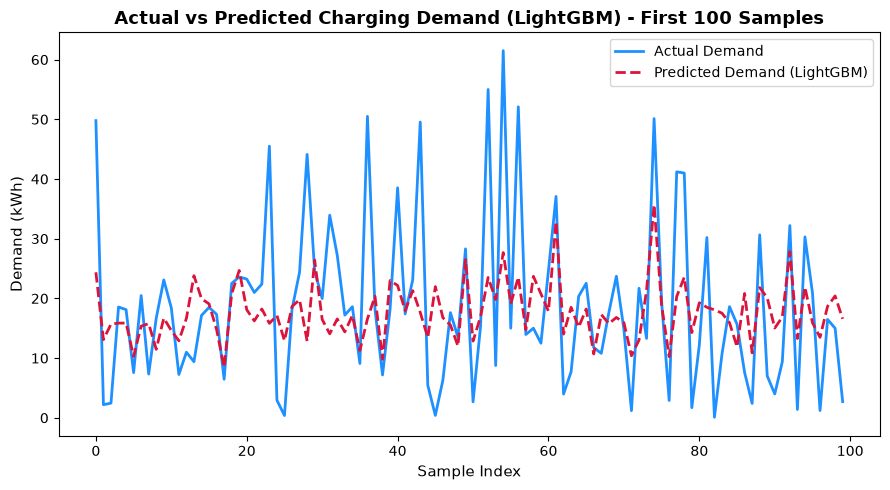

In [12]:
# Load the saved model
loaded_model = joblib.load(
    "../trained_models/best_regression_model.pkl"
)

# Predict demand using the saved model
predictions = loaded_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

# Display results
print("===== Regression Model Evaluation =====")
print(f"Model: {best_model_name}")
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

# Plot Actual vs Predicted Demand
plt.figure(figsize=(9, 5))
sample_size = 100
plt.plot(np.array(y_test)[:sample_size], label="Actual Demand", color="dodgerblue", linewidth=2)
plt.plot(predictions[:sample_size], label=f"Predicted Demand ({best_model_name})", color="crimson", linestyle="--", linewidth=2)
plt.title(f"Actual vs Predicted Charging Demand ({best_model_name}) - First 100 Samples", fontsize=13, fontweight="bold")
plt.xlabel("Sample Index", fontsize=11)
plt.ylabel("Demand (kWh)", fontsize=11)
plt.legend(frameon=True)

plt.savefig("../outputs/regression_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
print("Saved actual vs predicted chart to ../outputs/regression_actual_vs_predicted.png")

plt.tight_layout()
plt.show()